# Importing Libraries

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import tarfile
import os
import missingno as msno
import random
from sklearn.preprocessing import StandardScaler

# Pre-processing Pipeline

# 1. Data Collection

In [5]:
file_path = '../data/deux_fibre.csv'
data = pd.read_csv(file_path, sep=',')
data.head()

,ID,Tipo de fibra 1,Tipo de fibra 2,Dias curado,Dosage 1 (Kg/m3),Dosage 2 (Kg/m3),% Celulosa 1,% Celulosa 2,MEB 1,MEB 2,...,Etalement t=0 (mm),Teneur en air (%),Masse volumique (Kg/m3),Retrait,Coef.absorcion t=1 (%) Fibre 1,Coef.absorcion t=5 (%) Fibre 1,Coef.absorcion t=2880 (%) Fibre 1,Coef.absorcion t=1 (%) Fibre 2,Coef.absorcion t=5 (%) Fibre 2,Coef.absorcion t=2880 (%) Fibre 2
0,M1,CH5,B15,1.0,0.6,1.8,72,50,1,4,...,442.5,4.40,2.148,6.0,84.80,121.57,135.27,48.70,64.37,89.70
1,M2,CH5,M15,1.0,0.6,1.8,72,47,1,3,...,460.0,4.25,2.148,7.0,84.80,121.57,135.27,154.73,180.07,277.07
2,M3,L6,B15,1.0,0.6,1.8,71,50,2,4,...,437.5,4.00,2.15,4.0,21.30,34.23,155.27,48.70,64.37,89.70
3,M4,L6,M15,1.0,0.6,1.8,71,47,2,3,...,457.5,4.30,2.14,5.0,21.30,34.23,155.27,154.73,180.07,277.07
4,M5,CH.ANTIF. Antif,NO,1.0,0.6,0.0,Syntéthique,Syntéthique,Syntéthique,Syntéthique,...,395.0,NaN,NaN,1.0,Syntéthique,Syntéthique,Syntéthique,Syntéthique,Syntéthique,Syntéthique


In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 197 entries, 0 to 196
Data columns (total 22 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   ID                                 196 non-null    str    
 1   Tipo de fibra 1                    196 non-null    str    
 2   Tipo de fibra 2                    196 non-null    str    
 3   Dias curado                        196 non-null    float64
 4   Dosage 1 (Kg/m3)                   196 non-null    float64
 5   Dosage 2 (Kg/m3)                   196 non-null    float64
 6   % Celulosa 1                       196 non-null    str    
 7   % Celulosa 2                       196 non-null    str    
 8   MEB 1                              196 non-null    str    
 9   MEB 2                              196 non-null    str    
 10  Rf (MPa)                           148 non-null    float64
 11  Rc (MPa)                           148 non-null    float64
 12  Etale

In [7]:
data.describe()

,Dias curado,Dosage 1 (Kg/m3),Dosage 2 (Kg/m3),Rf (MPa),Rc (MPa),Etalement t=0 (mm),Teneur en air (%),Retrait
count,196.000000,196.000000,196.000000,148.000000,148.000000,148.000000,140.000000,196.000000
mean,31.750000,0.734694,1.836735,6.010473,23.187432,453.162162,4.058571,4.000000
std,35.737989,0.356364,1.224484,1.788795,7.900655,22.767101,0.561663,2.005122
min,1.000000,0.000000,0.000000,1.510000,4.340000,395.000000,3.000000,1.000000
25%,5.500000,0.600000,0.000000,4.682500,15.425000,442.500000,4.000000,2.000000
50%,17.500000,0.800000,2.400000,6.430000,25.350000,452.500000,4.300000,4.000000
75%,43.750000,1.000000,2.800000,7.270000,29.070000,460.000000,4.400000,6.000000
max,91.000000,1.200000,3.200000,9.980000,35.210000,490.000000,4.800000,7.000000


# 2. Data Cleaning

## 2.1 Missing Values

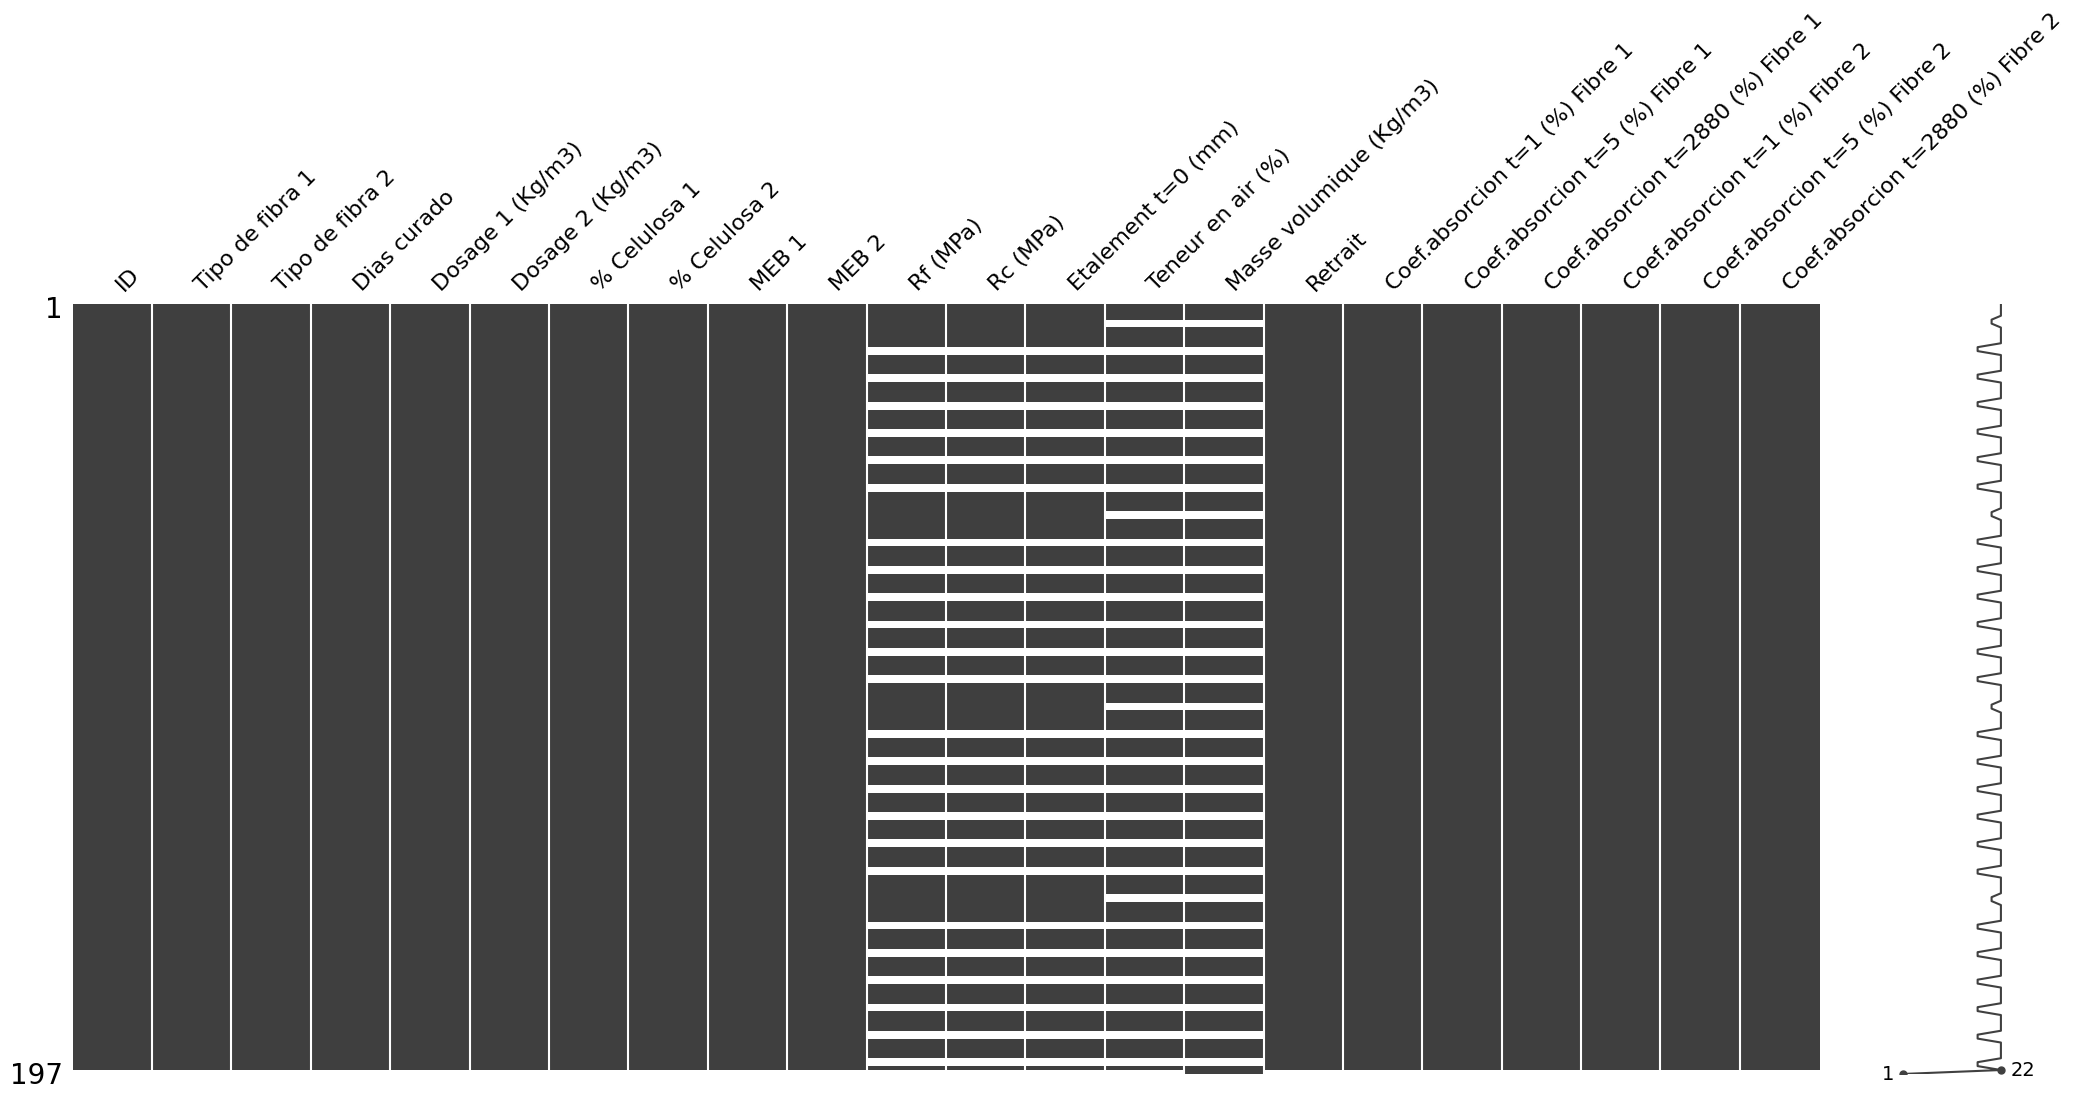

In [8]:
# Visualize missing data
msno.matrix(data)
plt.show()

In [9]:
def show_metric(data, column):
    print("=" * 50)
    print(f"{column:^50}")
    print("=" * 50)
    print(f"{'Données manquantes':<35} {data[column].isna().sum():>10}")
    print(f"{'% manquantes':<35} {round((data[column].isna().sum() / len(data)) * 100, 2):>9}%")
    print(f"{'Données disponibles':<35} {data[column].notna().sum():>10}")
    print(f"Lignes non alignées avec la colonne cible : {len([index for index, row in data.iterrows() if pd.isna(row[column]) and not pd.isna(row['Rc (MPa)'])])}")
    print("=" * 50)

show_metric(data, 'Rc (MPa)')

                     Rc (MPa)                     
Données manquantes                          49
% manquantes                            24.87%
Données disponibles                        148
Lignes non alignées avec la colonne cible : 0


<p style="color: grey;">
The dataset has <strong>49 missing values</strong> for compressive strength (Rc), reducing the number of usable rows to <strong>148 valid rows</strong>. This constraint directly influences the model choice, as an Artificial Neural Network (ANN) generally requires a larger data volume to generalize correctly. We will therefore lean towards models known for better performance on smaller datasets: <strong>Random Forest, XGBoost, SVR (Support Vector Regression)</strong> and <strong>Decision Tree</strong>.
</p>

In [10]:
show_metric(data, 'Rf (MPa)')
show_metric(data, 'Etalement t=0 (mm)')
show_metric(data, 'Teneur en air (%)')
show_metric(data, 'Masse volumique (Kg/m3)')

                     Rf (MPa)                     
Données manquantes                          49
% manquantes                            24.87%
Données disponibles                        148
Lignes non alignées avec la colonne cible : 0
                Etalement t=0 (mm)                
Données manquantes                          49
% manquantes                            24.87%
Données disponibles                        148
Lignes non alignées avec la colonne cible : 0
                Teneur en air (%)                 
Données manquantes                          57
% manquantes                            28.93%
Données disponibles                        140
Lignes non alignées avec la colonne cible : 8
             Masse volumique (Kg/m3)              
Données manquantes                          56
% manquantes                            28.43%
Données disponibles                        141
Lignes non alignées avec la colonne cible : 8


<p style="color: grey;">
The missing values across columns do not all align with the same rows as those missing for Rc (MPa). Specifically, 8 rows in the <strong>Air content</strong> and <strong>Bulk density</strong> columns have missing values that do not coincide with the missing rows of the target column. These residual missing values will be handled separately in the next section (imputation by median, mean, etc.). Therefore, after removing the 49 rows without an Rc value, all remaining columns can be kept for model training.
</p>

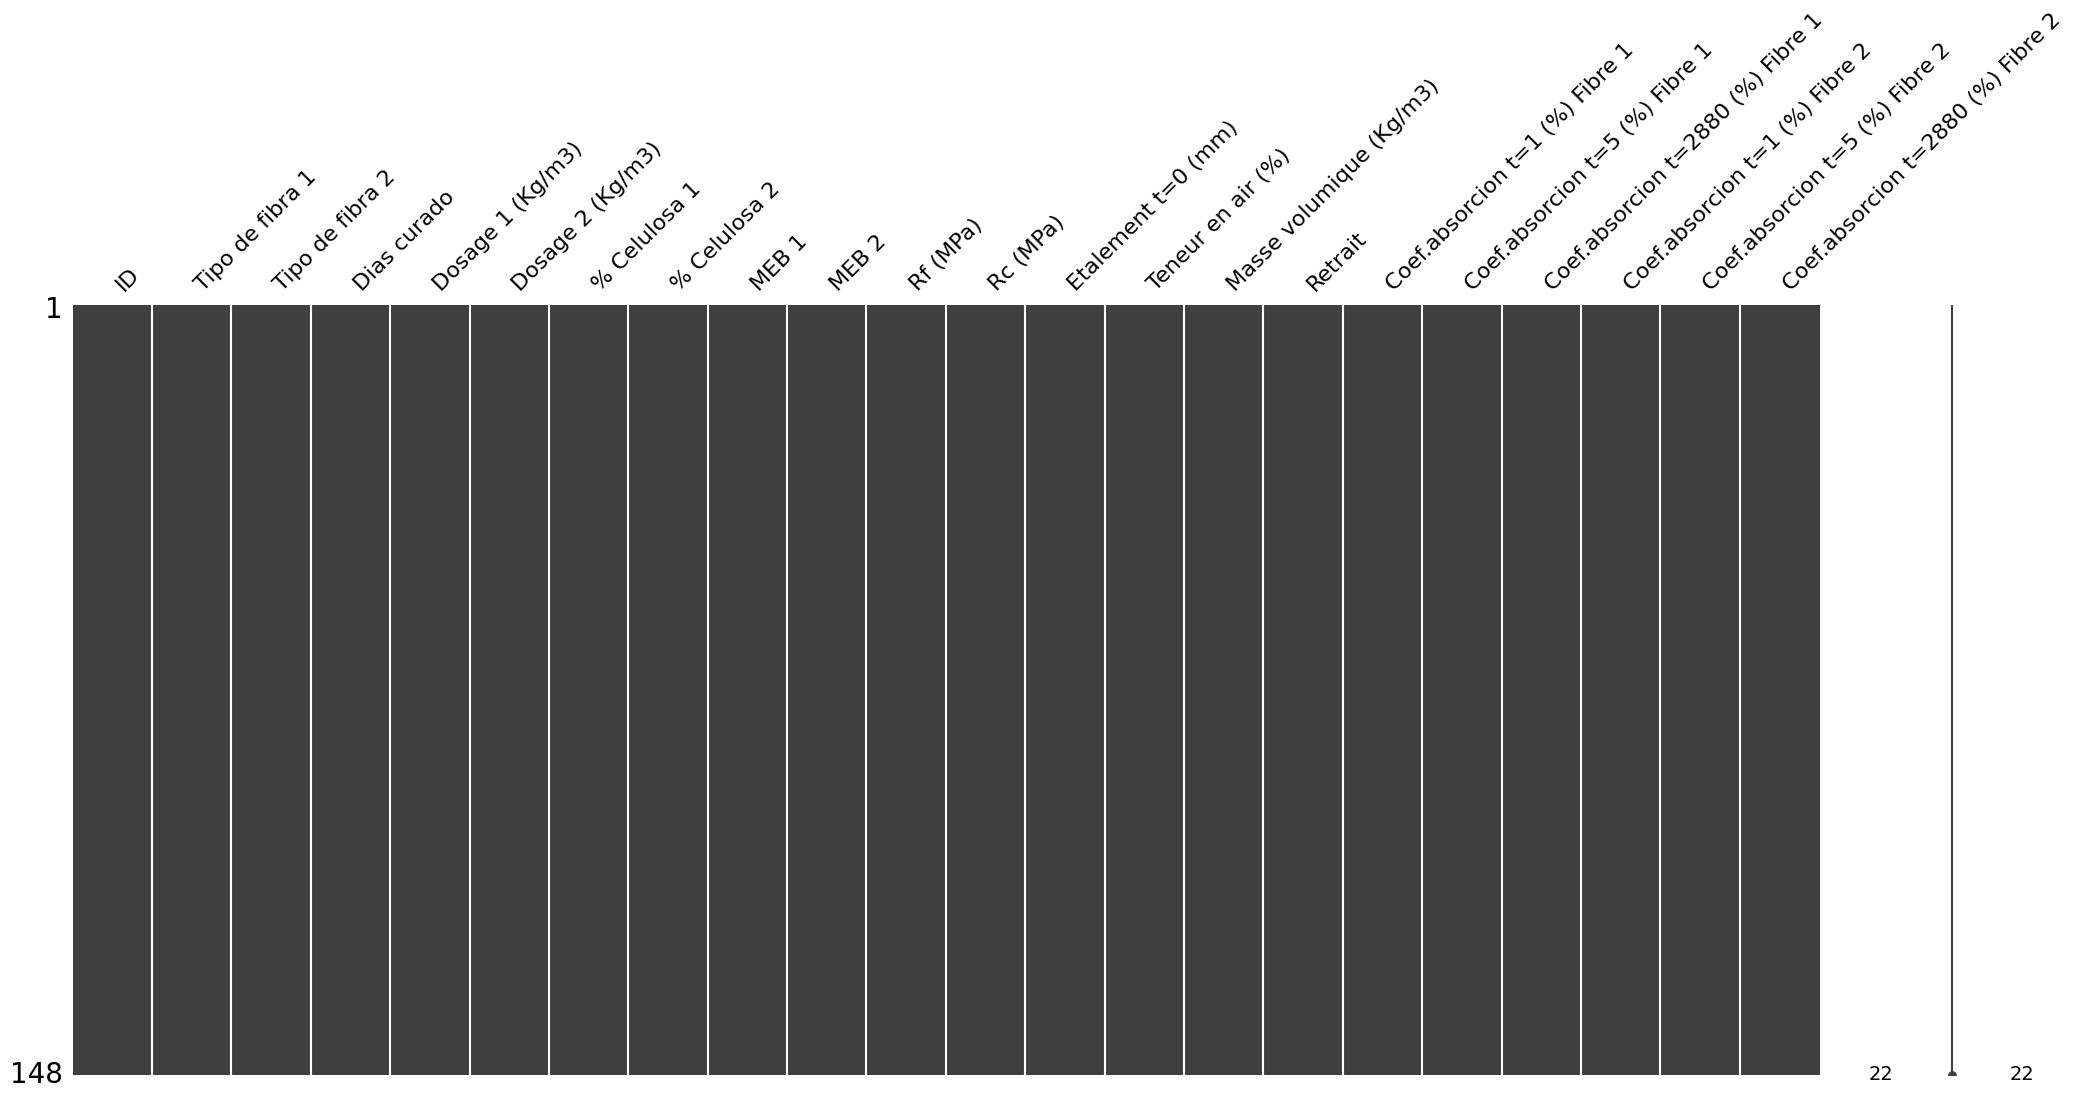

In [11]:
#suppression des lignes avec des valeurs manquantes dans la colonne cible
data = data.dropna(subset=['Rc (MPa)'])
#traitement des valeurs manquantes dans les autres colonnes
data['Masse volumique (Kg/m3)'] = pd.to_numeric(data['Masse volumique (Kg/m3)'], errors='coerce')
data['Masse volumique (Kg/m3)'] = data['Masse volumique (Kg/m3)'] .fillna(data['Masse volumique (Kg/m3)'].median())
data['Teneur en air (%)'] = data['Teneur en air (%)'].fillna(data['Teneur en air (%)'].median())
# Visualize missing data
msno.matrix(data)
plt.show()

<p style="color: grey;">
After handling missing values, the dataset contains no more null values and is ready for model training.
</p>

## 2.2 Outliers

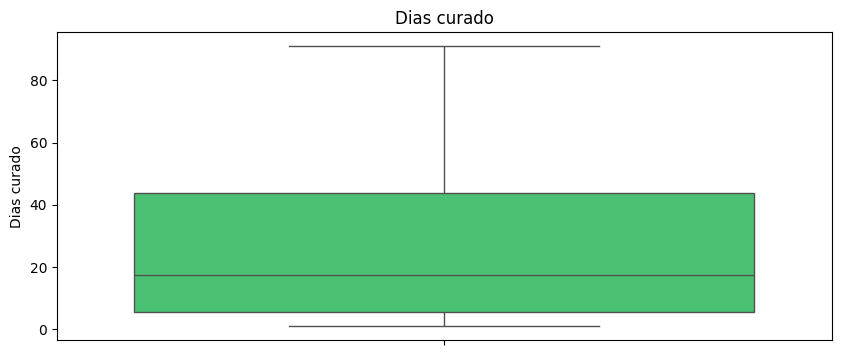

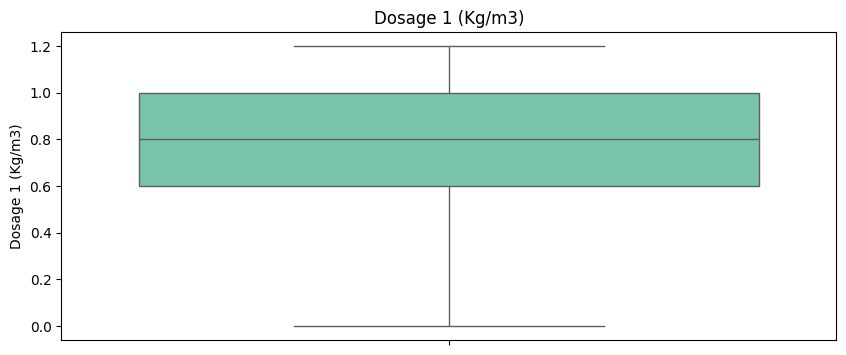

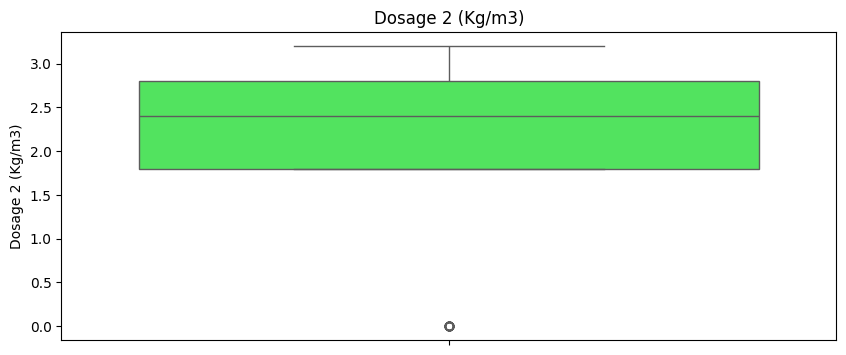

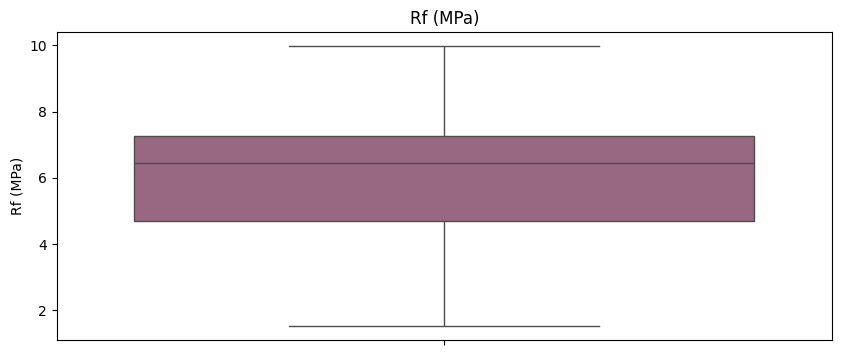

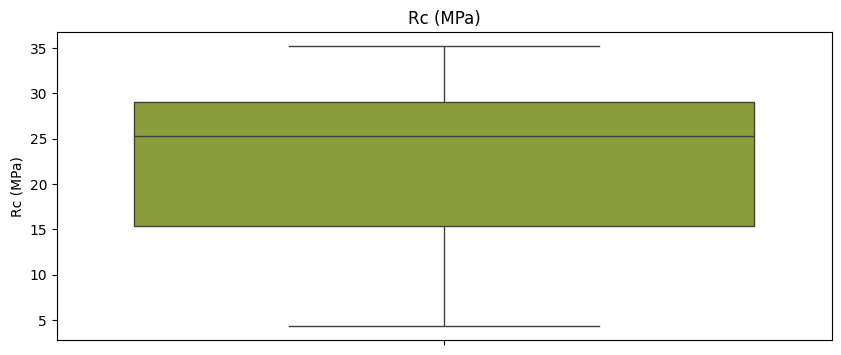

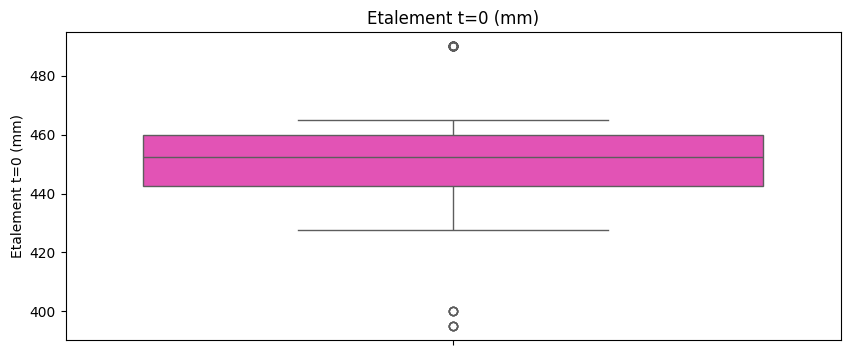

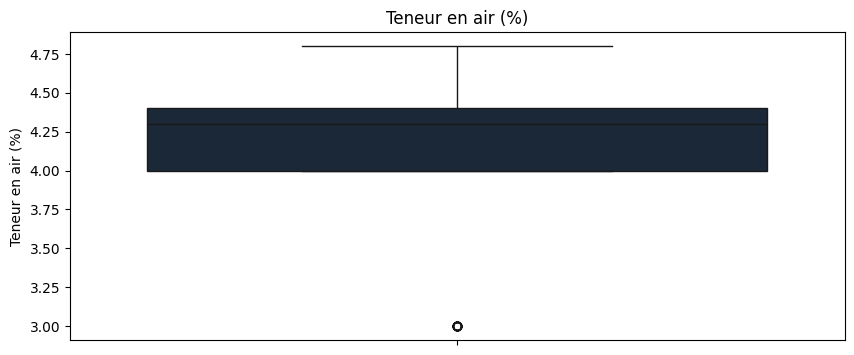

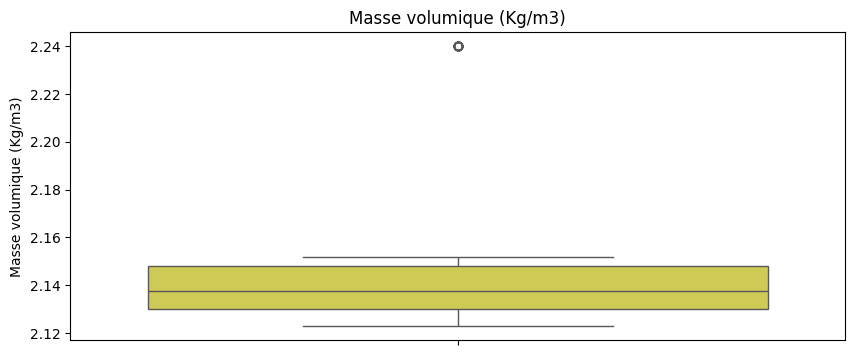

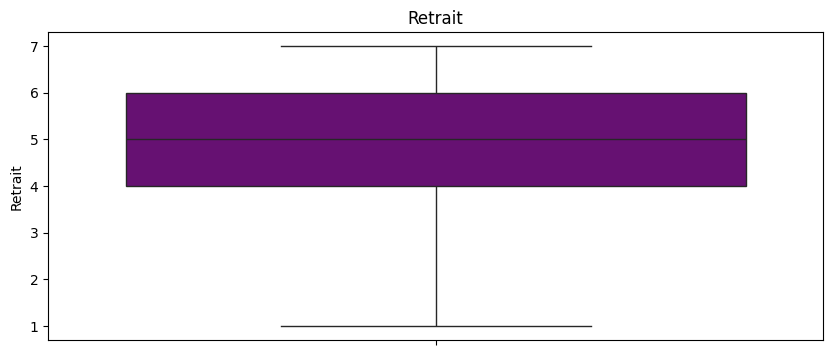

In [12]:
numerical_columns = data.select_dtypes(include=['float64', 'int64']).columns
for column in numerical_columns:
    plt.figure(figsize=(10, 4))
    sns.boxplot(y=data[column], color=tuple(np.random.rand(3)))
    plt.title(f'{column}')

    plt.show()

<p style="color: grey;">
Very few outliers are observed in the dataset. In our experimental context, these values do not result from measurement or entry errors, but reflect real mix design conditions of fiber-reinforced mortar. They therefore represent valuable information for model training, as they help cover a wider range of mechanical behaviors. These values will be kept as is.
</p>

## 2.3 Categorical Values

In [13]:
categorical_columns = data.select_dtypes(include=['object']).columns
# Count the number of values that are represented in categorical columns
for column in categorical_columns:
    value_counts = data[column].value_counts()
    print(f'{column}:\n{value_counts}\n')

ID:
ID
M1      1
M2      1
M3      1
M4      1
M5      1
       ..
M190    1
M191    1
M192    1
M193    1
M196    1
Name: count, Length: 148, dtype: int64

Tipo de fibra 1:
Tipo de fibra 1
CH5                  56
L6                   56
Témoin               28
CH.ANTIF. Antif       4
CH.STRUCT. Antif.     4
Name: count, dtype: int64

Tipo de fibra 2:
Tipo de fibra 2
B15                 56
M15                 56
NO                  32
CH.STRUCT. Strux     4
Name: count, dtype: int64

% Celulosa 1:
% Celulosa 1
72             56
71             56
Témoin         28
Syntéthique     8
Name: count, dtype: int64

% Celulosa 2:
% Celulosa 2
50             56
47             56
Témoin         28
Syntéthique     8
Name: count, dtype: int64

MEB 1:
MEB 1
1              56
2              56
Témoin         28
Syntéthique     8
Name: count, dtype: int64

MEB 2:
MEB 2
4              56
3              56
Témoin         28
Syntéthique     8
Name: count, dtype: int64

Coef.absorcion t=1 (%) Fibre 1:
Coe

C:\Users\matte\AppData\Local\Temp\ipykernel_18132\1351754899.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = data.select_dtypes(include=['object']).columns


<p style="color: grey;">Some columns (% Celulosa, Coef.absorcion) contain categorical values (Témoin, Synthétique) instead of numeric values. The Témoin values indicate no fiber present (zero absorption), and Synthétique indicates a non-cellulosic fiber whose absorption is considered negligible. Both are replaced by 0. The MEB 1 and MEB 2 columns, which represent morphology observed under electron microscopy, are one-hot encoded since their values are categorical codes. Finally, a binary feature is_temoin is created before dropping the Tipo de fibra columns. Combined with the MEB one-hot encoding, it allows the model to distinguish the three cases: control concrete, synthetic fiber, and cellulosic fiber.</p>

In [14]:
# Delete tipo fiber 1 and tipo fiber 2 to avoid collinearity with cellulose percentages
 
data['is_temoin'] = (data['Tipo de fibra 1'] == 'Témoin').astype(int)
data.drop(['Tipo de fibra 1', 'Tipo de fibra 2'], axis=1, inplace=True)

#  Value that should be 0 for controls and synthetics
cols_to_fix = [col for col in data.columns if any(x in col for x in ['Coef.absorcion', '% Celulosa'])]
for col in cols_to_fix:
    data[col] = pd.to_numeric(data[col], errors='coerce').fillna(0)

# One hot encoding for the meb1 and meb2 columns (we can’t set them to 0)
# MEB 1
data.loc[data['MEB 1'] == 'Témoin', 'MEB 1'] = '0'
data.loc[data['MEB 1'] == 'Syntéthique', 'MEB 1'] = '0'
# MEB 2
data.loc[data['MEB 2'] == 'Témoin', 'MEB 2'] = '0'
data.loc[data['MEB 2'] == 'Syntéthique', 'MEB 2'] = '0'

data['MEB 1'] = data['MEB 1'].astype(int)
data['MEB 2'] = data['MEB 2'].astype(int)
data = pd.get_dummies(data, columns=['MEB 1', 'MEB 2'])

In [15]:
#afficher les noms de colonne 
for column in data.columns:
    print(f'{column}:\n{data[column].value_counts()}\n')

ID:
ID
M1      1
M2      1
M3      1
M4      1
M5      1
       ..
M190    1
M191    1
M192    1
M193    1
M196    1
Name: count, Length: 148, dtype: int64

Dias curado:
Dias curado
1.0     37
7.0     37
28.0    37
91.0    37
Name: count, dtype: int64

Dosage 1 (Kg/m3):
Dosage 1 (Kg/m3)
0.6    40
1.0    32
0.8    32
0.0    28
1.2    16
Name: count, dtype: int64

Dosage 2 (Kg/m3):
Dosage 2 (Kg/m3)
0.0    32
1.8    20
2.2    16
2.4    16
2.6    16
3.2    16
3.0    16
2.8    16
Name: count, dtype: int64

% Celulosa 1:
% Celulosa 1
72.0    56
71.0    56
0.0     36
Name: count, dtype: int64

% Celulosa 2:
% Celulosa 2
50.0    56
47.0    56
0.0     36
Name: count, dtype: int64

Rf (MPa):
Rf (MPa)
8.20    7
6.84    6
6.58    5
4.24    4
7.15    4
       ..
8.96    1
7.32    1
8.29    1
8.30    1
7.10    1
Name: count, Length: 111, dtype: int64

Rc (MPa):
Rc (MPa)
25.35    7
30.25    7
33.22    7
14.18    4
14.19    3
        ..
35.21    1
29.18    1
28.03    1
30.41    1
26.28    1
Name: coun

<p>Convert str column into numeric (if possible)</p>

In [16]:
print(data.columns)
# convert data in numerical format
data['Etalement t=0 (mm)'] = pd.to_numeric(data['Etalement t=0 (mm)'])
data['Teneur en air (%)'] = pd.to_numeric(data['Teneur en air (%)'])
data['Masse volumique (Kg/m3)'] = pd.to_numeric(data['Masse volumique (Kg/m3)'])
data['Dias curado'] = pd.to_numeric(data['Dias curado'])

print(data.head())
print(data.info())

Index(['ID', 'Dias curado', 'Dosage 1 (Kg/m3)', 'Dosage 2 (Kg/m3)',
       '% Celulosa 1', '% Celulosa 2', 'Rf (MPa)', 'Rc (MPa)',
       'Etalement t=0 (mm)', 'Teneur en air (%)', 'Masse volumique (Kg/m3)',
       'Retrait', 'Coef.absorcion t=1 (%) Fibre 1',
       'Coef.absorcion t=5 (%) Fibre 1', 'Coef.absorcion t=2880 (%) Fibre 1',
       'Coef.absorcion t=1 (%) Fibre 2', 'Coef.absorcion t=5 (%) Fibre 2',
       'Coef.absorcion t=2880 (%) Fibre 2', 'is_temoin', 'MEB 1_0', 'MEB 1_1',
       'MEB 1_2', 'MEB 2_0', 'MEB 2_3', 'MEB 2_4'],
      dtype='str')
   ID  Dias curado  Dosage 1 (Kg/m3)  Dosage 2 (Kg/m3)  % Celulosa 1  \
0  M1          1.0               0.6               1.8          72.0   
1  M2          1.0               0.6               1.8          72.0   
2  M3          1.0               0.6               1.8          71.0   
3  M4          1.0               0.6               1.8          71.0   
4  M5          1.0               0.6               0.0           0.0   

   %

# 4. CSV Export

In [17]:
#export en csv 
data.to_csv('../data/2_cleaned_data.csv', index=False)